# 01 – Collecte, nettoyage, équilibrage et séparation des données Sentinel-2

**Ce notebook fait tout le travail de données**, de la collecte au jeu final prêt pour l'entraînement :

1. **Collecte** de chips 256×256 (4 bandes B02, B03, B04, B08) depuis **Microsoft Planetary Computer** (données Copernicus Sentinel-2 L2A). On lit seulement des *fenêtres* : aucune scène complète n'est téléchargée, aucun compte n'est nécessaire.
2. **Prise en compte des nuages** : les chips sont classées avec la bande SCL (classification de scène) **et** un test de brume sur le bleu.
   - *propres* : au plus 2 % de pixels nuageux ou douteux ;
   - *difficiles* (« hard ») : de **vrais** nuages, ombres, neige ou brume (5 à 60 %). Elles restent des images **authentiques**. Elles servent de négatifs réels pour que le détecteur n'apprenne pas « nuage = falsifié ».
3. **Nettoyage** : pixels vides, saturation, chips plates, doublons, chips presque uniquement de l'eau.
4. **Équilibrage** : même poids pour chaque région, 4 saisons représentées, scènes choisies par saison.
5. **Séparation sans fuite** : par **tuile MGRS** (zones géographiquement distinctes), stratifiée par région, saison et nuages, + une **région étrangère** (Sicile) réservée au test externe.
6. **Visualisations** de chaque contrôle, puis **sauvegarde** avec empreintes SHA-256 (le notebook d'entraînement vérifiera qu'aucun fichier n'a été corrompu ou modifié).

**Avant de lancer (Kaggle) :** panneau de droite, *Session options* : **Internet = On**. Le GPU n'est pas nécessaire ici.

> `QUICK = True` fait un test de quelques minutes (dossiers `*_quick`). Si tout passe, mettez `QUICK = False` : c'est la vraie collecte, d'environ 1 à 1,5 heure.

**Résultat :** dossier `data_split/`. Ensuite : *Save Version* → *Save & Run All (Commit)* → onglet *Output* → *New Dataset* → nom `tp-data`.

In [1]:
!pip -q install pystac-client planetary-computer rasterio

In [2]:
import os, random, time, json, math, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import rasterio, planetary_computer as pc, pystac_client
from rasterio.windows import Window, from_bounds
from rasterio.warp import transform_bounds, transform as rio_transform
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

QUICK = False            # True = test rapide ; False = vraie collecte
SEED = 42
random.seed(SEED); np.random.seed(SEED)

IN_KAGGLE = Path('/kaggle').exists()
ROOT = Path('/kaggle/working') if IN_KAGGLE else Path('/content')
SUF = '_quick' if QUICK else ''
RAW = ROOT / f'chips_raw{SUF}'
OUT = ROOT / f'data_split{SUF}'
RAW.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)

STAC_URL = 'https://planetarycomputer.microsoft.com/api/stac/v1'
DATES = '2023-01-01/2026-09-30'          # >= baseline 04.00 : réflectance = (DN - 1000) / 10000
BANDS = ['B02', 'B03', 'B04', 'B08']     # bleu, vert, rouge, proche infrarouge (10 m)
SIZE = 256
BAD_SCL = [0, 1, 3, 8, 9, 10, 11]        # sans donnée, saturé, ombre, nuages (moyen et haut), cirrus, neige
SEASONS = ['DJF', 'MAM', 'JJA', 'SON']

MAX_CLOUD_CLEAN = 10                     # scènes « propres » : moins de 10 % de nuages
MAX_CLOUD_SEARCH = 35                    # scènes « difficiles » : 10 à 35 %
CLEAN_BAD_MAX = 0.02                     # chip propre : au plus 2 % de pixels douteux (SCL)
HARD_BAD_MIN, HARD_BAD_MAX = 0.05, 0.60  # chip difficile : 5 à 60 % de vrais nuages / ombres / neige
HAZE_B02, HAZE_CLEAN_MAX, HAZE_HARD_MIN = 0.25, 0.02, 0.05   # brume : part de pixels bleus très brillants

SCENES_PER_REGION = 8                    # 2 par saison
CHIPS_PER_SCENE = 50
HARD_SCENES_PER_REGION = 2
HARD_CHIPS_PER_SCENE = 15

# nom : (boîte lon_min, lat_min, lon_max, lat_max, rôle)
REGIONS = {
    'nord_tunis':      ([9.9, 36.6, 10.5, 37.1], 'tn'),
    'nord_beja':       ([9.0, 36.6, 9.6, 37.1], 'tn'),
    'centre_kairouan': ([9.8, 35.4, 10.4, 35.9], 'tn'),
    'centre_sfax':     ([10.4, 34.5, 11.0, 35.0], 'tn'),
    'sud_tozeur':      ([8.0, 33.7, 8.5, 34.1], 'tn'),
    'sud_gabes':       ([9.9, 33.7, 10.4, 34.1], 'tn'),
    'etranger_sicile': ([14.0, 37.3, 14.6, 37.8], 'foreign'),   # test de changement de géographie
}
if QUICK:
    SCENES_PER_REGION, CHIPS_PER_SCENE, HARD_SCENES_PER_REGION, HARD_CHIPS_PER_SCENE = 4, 8, 1, 5
    REGIONS = {k: REGIONS[k] for k in ['nord_tunis', 'centre_sfax', 'sud_gabes', 'etranger_sicile']}
print('dossier brut :', RAW, '| dossier final :', OUT)

dossier brut : /kaggle/working/chips_raw | dossier final : /kaggle/working/data_split


## 1. Fonctions de lecture (fenêtres COG) et classification des chips

Une chip est classée **propre**, **difficile** ou **ambiguë** (écartée) selon la part de pixels douteux (bande SCL) et la part de pixels très brillants dans le bleu (brume, nuages fins que SCL rate parfois). Pour chaque chip on garde aussi la **géoréférence** (projection, coin haut-gauche, longitude, latitude), utile pour la carte et pour exporter en GeoTIFF vers QGIS.

In [3]:
def season_of(date_str):
    m = int(str(date_str)[5:7])
    return 'DJF' if m in (12, 1, 2) else 'MAM' if m in (3, 4, 5) else 'JJA' if m in (6, 7, 8) else 'SON'

def baseline_offset(props):
    # depuis la baseline 04.00 (25 janvier 2022), les valeurs numériques sont décalées de +1000
    try:
        return 1000 if float(props.get('s2:processing_baseline', '0')) >= 4.0 else 0
    except (TypeError, ValueError):
        return 0

def aoi_window(src, bbox):
    l, b, r, t = transform_bounds('EPSG:4326', src.crs, *bbox)
    w = from_bounds(l, b, r, t, src.transform)
    r0, c0 = max(int(w.row_off), 0), max(int(w.col_off), 0)
    r1 = min(int(w.row_off + w.height), src.height)
    c1 = min(int(w.col_off + w.width), src.width)
    return r0, r1, c0, c1

def classify_chip(bad, haze):
    if bad <= CLEAN_BAD_MAX and haze <= HAZE_CLEAN_MAX:
        return 'clean'
    if HARD_BAD_MIN <= bad <= HARD_BAD_MAX or HAZE_HARD_MIN <= haze <= HARD_BAD_MAX:
        return 'hard'
    return 'ambiguous'

def chip_georef(src, r0, c0, size=SIZE):
    tr = src.window_transform(Window(c0, r0, size, size))
    x0, y0 = float(tr.c), float(tr.f)
    xc, yc = x0 + size * 5.0, y0 - size * 5.0                     # centre (pixels de 10 m)
    lon, lat = rio_transform(src.crs, 'EPSG:4326', [xc], [yc])
    return dict(epsg=int(src.crs.to_epsg() or 0), x0=x0, y0=y0, lon=float(lon[0]), lat=float(lat[0]))

def sample_scene(region, role, bbox, item, want, n, tries_factor=12, rnd=None):
    # lit au plus n chips de la classe `want` ('clean' ou 'hard') dans la scène, sans chevauchement
    rnd = rnd or random
    item = pc.sign(item)                                       # jeton d'accès temporaire
    srcs = {b: rasterio.open(item.assets[b].href) for b in BANDS}
    scl = rasterio.open(item.assets['SCL'].href)               # 20 m
    off = baseline_offset(item.properties)
    chips, meta, placed, counts = [], [], [], {'clean': 0, 'hard': 0, 'ambiguous': 0, 'vide': 0}
    try:
        r0a, r1a, c0a, c1a = aoi_window(srcs['B02'], bbox)
        if r1a - r0a <= SIZE or c1a - c0a <= SIZE:
            return [], [], counts
        tries = 0
        while len(chips) < n and tries < n * tries_factor:
            tries += 1
            r0 = rnd.randrange(r0a, r1a - SIZE); r0 -= r0 % 2
            c0 = rnd.randrange(c0a, c1a - SIZE); c0 -= c0 % 2
            if any(abs(r0 - r) < SIZE and abs(c0 - c) < SIZE for r, c in placed):
                continue
            s = scl.read(1, window=Window(c0 // 2, r0 // 2, SIZE // 2, SIZE // 2),
                         out_shape=(SIZE, SIZE), resampling=Resampling.nearest)
            bad = float(np.isin(s, BAD_SCL).mean())
            if bad > HARD_BAD_MAX or (want == 'clean' and bad > HARD_BAD_MIN):
                counts['ambiguous'] += 1; continue              # inutile de lire les 4 bandes
            x = np.stack([srcs[b].read(1, window=Window(c0, r0, SIZE, SIZE)) for b in BANDS])
            if (x == 0).mean() > 0.01:
                counts['vide'] += 1; continue
            haze = float((((x[0].astype(np.float32) - off) / 10000.0) > HAZE_B02).mean())
            kind = classify_chip(bad, haze)
            counts[kind] += 1
            if kind != want:
                continue
            chips.append(x.astype(np.uint16)); placed.append((r0, c0))
            meta.append(dict(region=region, role=role, scene=item.id, tile=item.properties['s2:mgrs_tile'],
                             date=item.properties['datetime'][:10], season=season_of(item.properties['datetime'][:10]),
                             cloud_scene=float(item.properties.get('eo:cloud_cover', np.nan)),
                             baseline=item.properties.get('s2:processing_baseline'), offset=off, r0=r0, c0=c0,
                             bad_frac=round(bad, 4), haze_frac=round(haze, 4), hard=(kind == 'hard'),
                             **chip_georef(srcs['B02'], r0, c0)))
    finally:
        for s_ in srcs.values():
            s_.close()
        scl.close()
    return chips, meta, counts

## 2. Recherche des scènes (aucun pixel lu), choisies **par saison**

- Les scènes « propres » (moins de 10 % de nuages) sont réparties **également entre les 4 saisons**. Si une saison manque de scènes propres (l'hiver est souvent nuageux), on complète avec des scènes plus nuageuses de cette saison : le filtre au niveau des chips garde de toute façon uniquement les zones propres.
- Quelques scènes **nuageuses** (10 à 35 %) servent à récupérer de **vrais nuages et ombres** comme négatifs authentiques.

In [4]:
catalog = pystac_client.Client.open(STAC_URL, modifier=pc.sign_inplace)
rnd_sel = random.Random(SEED)

def pick_scenes(clean_pool, relaxed_pool, k):
    by_season = {s: [] for s in SEASONS}
    for it in clean_pool:
        by_season[season_of(it.properties['datetime'][:10])].append(it)
    rel = {s: [] for s in SEASONS}
    for it in relaxed_pool:
        rel[season_of(it.properties['datetime'][:10])].append(it)
    per = max(1, k // 4)
    picked = []
    for s in SEASONS:
        rnd_sel.shuffle(by_season[s]); rnd_sel.shuffle(rel[s])
        picked += (by_season[s] + rel[s])[:per]
    return picked

selected = []                     # (région, rôle, bbox, scène, type)
for name, (bbox, role) in REGIONS.items():
    items = list(catalog.search(collections=['sentinel-2-l2a'], bbox=bbox, datetime=DATES,
                                query={'eo:cloud_cover': {'lt': MAX_CLOUD_SEARCH}}).items())
    clean_pool = [it for it in items if it.properties['eo:cloud_cover'] < MAX_CLOUD_CLEAN]
    relaxed_pool = [it for it in items if it.properties['eo:cloud_cover'] >= MAX_CLOUD_CLEAN]
    picks = pick_scenes(clean_pool, relaxed_pool, SCENES_PER_REGION)
    rest = [it for it in relaxed_pool if it not in picks]
    rnd_sel.shuffle(rest)
    hard_picks = rest[:HARD_SCENES_PER_REGION]
    print(f'{name}: {len(items)} scènes (dont {len(clean_pool)} propres) -> {len(picks)} propres + {len(hard_picks)} nuageuses')
    selected += [(name, role, bbox, it, 'clean') for it in picks] + [(name, role, bbox, it, 'hard') for it in hard_picks]
print(len(selected), 'scènes retenues')
print(pd.Series([season_of(s[3].properties['datetime'][:10]) for s in selected]).value_counts().reindex(SEASONS).to_dict())

nord_tunis: 1723 scènes (dont 1104 propres) -> 8 propres + 2 nuageuses
nord_beja: 1080 scènes (dont 736 propres) -> 8 propres + 2 nuageuses
centre_kairouan: 964 scènes (dont 701 propres) -> 8 propres + 2 nuageuses
centre_sfax: 254 scènes (dont 188 propres) -> 8 propres + 2 nuageuses
sud_tozeur: 538 scènes (dont 438 propres) -> 8 propres + 2 nuageuses
sud_gabes: 529 scènes (dont 403 propres) -> 8 propres + 2 nuageuses
etranger_sicile: 217 scènes (dont 133 propres) -> 8 propres + 2 nuageuses
70 scènes retenues
{'DJF': 17, 'MAM': 18, 'JJA': 17, 'SON': 18}


## 3. Lecture par fenêtres, sauvegarde reprenable
Chaque scène produit un fichier `.npy` et un `.json`. Si la session s'arrête, relancez simplement la cellule : les scènes déjà faites sont sautées.

In [5]:
t0 = time.time()
gdal_env = rasterio.Env(GDAL_HTTP_TIMEOUT=30, GDAL_HTTP_MAX_RETRY=3, GDAL_HTTP_RETRY_DELAY=2,
                        GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR')
with gdal_env:
    for k, (region, role, bbox, item, want) in enumerate(selected):
        base = RAW / f'{region}__{item.id}__{want}'
        if base.with_suffix('.json').exists():
            continue
        n_want = CHIPS_PER_SCENE if want == 'clean' else HARD_CHIPS_PER_SCENE
        chips, meta_i, counts = [], [], {}
        for attempt in range(3):
            try:
                chips, meta_i, counts = sample_scene(region, role, bbox, item, want, n_want,
                                                     rnd=random.Random(SEED + k)); break
            except Exception as e:
                print('  erreur', type(e).__name__, str(e)[:100]); time.sleep(3 * 2 ** attempt)
        if not chips:
            print(f'[{k + 1}/{len(selected)}] scène ignorée {item.id[:40]} ({want}) {counts}'); continue
        for i, m in enumerate(meta_i):
            m['file'] = base.with_suffix('.npy').name; m['idx'] = i
        np.save(base.with_suffix('.npy'), np.stack(chips))
        json.dump(meta_i, open(base.with_suffix('.json'), 'w'))
        print(f'[{k + 1}/{len(selected)}] {region} {want:5s} {item.id[:38]} -> {len(chips)} chips  {counts}  ({(time.time() - t0) / 60:.1f} min)')

rows = []
for jf in sorted(RAW.glob('*.json')):
    rows += json.load(open(jf))
meta = pd.DataFrame(rows).reset_index(drop=True)
assert len(meta) > 0, 'aucune chip collectée : vérifiez Internet = On et les dates'
print(len(meta), 'chips collectées |', int(meta.hard.sum()), 'difficiles (vrais nuages)')

[1/70] nord_tunis clean S2B_MSIL2A_20241228T101339_R022_T32SPG -> 25 chips  {'clean': 25, 'hard': 0, 'ambiguous': 186, 'vide': 0}  (0.3 min)
[2/70] nord_tunis clean S2B_MSIL2A_20230214T100029_R122_T32SPF -> 50 chips  {'clean': 50, 'hard': 2, 'ambiguous': 60, 'vide': 0}  (0.9 min)
[3/70] nord_tunis clean S2A_MSIL2A_20260406T100051_R122_T32SPG -> 39 chips  {'clean': 39, 'hard': 0, 'ambiguous': 0, 'vide': 0}  (1.2 min)
[4/70] nord_tunis clean S2A_MSIL2A_20250531T100051_R122_T32SPG -> 36 chips  {'clean': 36, 'hard': 0, 'ambiguous': 2, 'vide': 0}  (1.4 min)
[5/70] nord_tunis clean S2B_MSIL2A_20230826T100559_R022_T32SNF -> 50 chips  {'clean': 50, 'hard': 4, 'ambiguous': 14, 'vide': 0}  (1.9 min)
[6/70] nord_tunis clean S2B_MSIL2A_20230724T095559_R122_T32SPG -> 38 chips  {'clean': 38, 'hard': 0, 'ambiguous': 1, 'vide': 0}  (2.1 min)
[7/70] nord_tunis clean S2A_MSIL2A_20230907T100031_R122_T32SPF -> 50 chips  {'clean': 50, 'hard': 37, 'ambiguous': 101, 'vide': 0}  (2.7 min)
[8/70] nord_tunis cl

chips en mémoire : (2419, 4, 256, 256) uint16 1.27 Go


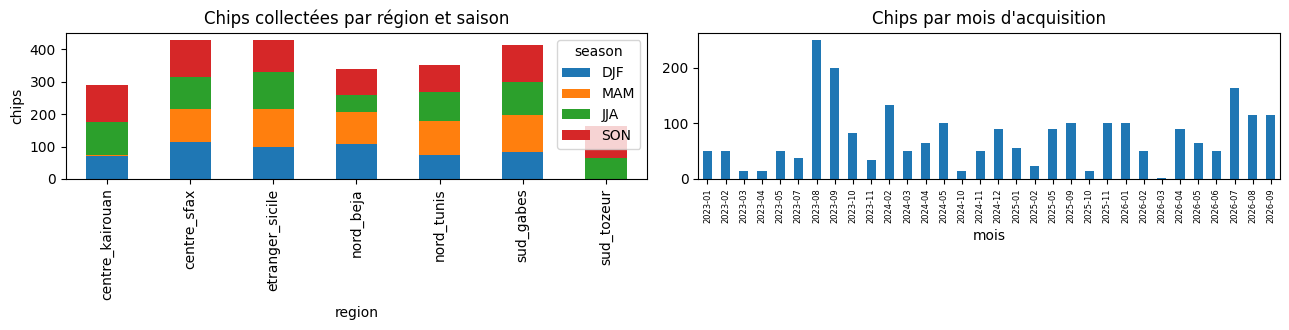

In [6]:
# chargement en mémoire + contrôles de forme
X = np.zeros((len(meta), len(BANDS), SIZE, SIZE), np.uint16)
for f, g in meta.groupby('file'):
    arr = np.load(RAW / f)
    assert arr.ndim == 4 and arr.shape[1:] == (len(BANDS), SIZE, SIZE), f'{f} : forme {arr.shape}'
    X[g.index.values] = arr[g['idx'].values]
print('chips en mémoire :', X.shape, X.dtype, f'{X.nbytes / 1e9:.2f} Go')

fig, axs = plt.subplots(1, 2, figsize=(13, 3.4))
meta.groupby(['region', 'season']).size().unstack().reindex(columns=SEASONS).plot.bar(ax=axs[0], stacked=True)
axs[0].set_title('Chips collectées par région et saison'); axs[0].set_ylabel('chips')
meta.assign(mois=meta.date.str[:7]).groupby('mois').size().plot.bar(ax=axs[1], color='tab:blue')
axs[1].set_title('Chips par mois d\'acquisition'); axs[1].tick_params(axis='x', labelsize=6)
plt.tight_layout(); plt.show()

## 4. Nettoyage

Contrôles recalculés **depuis les pixels** (on ne fait pas confiance aveuglément à la collecte) :

| Contrôle | Règle | Pourquoi |
|---|---|---|
| Pixels vides | plus de 1 % de zéros : retirée | bord de tuile ou erreur de lecture |
| Saturation (propres) | plus de 2 % de réflectance > 1 : retirée | pixels brûlés, reflets |
| Chip plate | écart-type < 5 DN sur une bande : retirée | aucune texture, inutile pour la détection |
| Doublons | contenu identique : un seul exemplaire | évite la fuite entre jeux |
| Eau quasi pure | plus de 90 % d'eau : limitée à 5 % des chips d'une région | peu d'information, trop faciles |
| Chips difficiles | gardées (authentiques) | vrais nuages, ombres, neige |

/tmp/ipykernel_23/2901032978.py:10: RuntimeWarning: divide by zero encountered in divide
  water_frac[i] = (((g - nir) / (g + nir + 1e-4)) > 0.1).mean()


retirées : 477 / 2419  | vides 0  saturées 0  plates 3  doublons 0  eau pure (excédent) 474


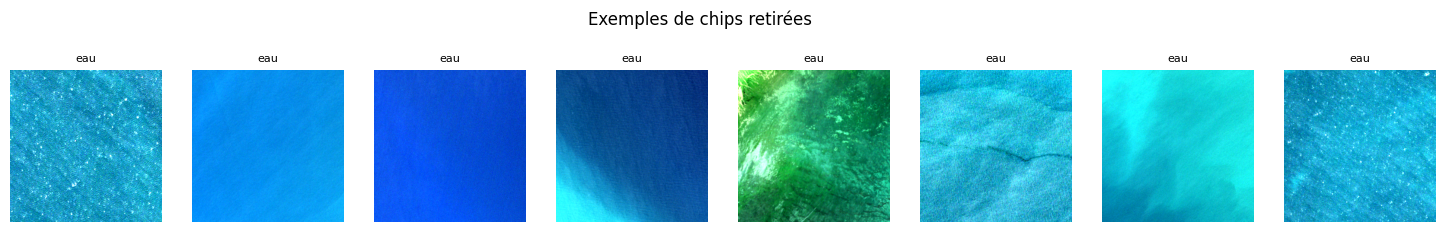

chips après nettoyage : 1942 | difficiles : 163


In [7]:
off = meta['offset'].values.astype(np.float32)
zero_frac = np.zeros(len(X)); sat_frac = np.zeros(len(X)); min_std = np.zeros(len(X)); water_frac = np.zeros(len(X))
for i in range(len(X)):
    x = X[i].astype(np.float32)
    refl = (x - off[i]) / 10000.0
    zero_frac[i] = (X[i] == 0).mean()
    sat_frac[i] = (refl > 1.0).mean()
    min_std[i] = x.std(axis=(1, 2)).min()
    g, nir = refl[1], refl[3]
    water_frac[i] = (((g - nir) / (g + nir + 1e-4)) > 0.1).mean()
meta['zero_frac'], meta['sat_frac'], meta['min_std'], meta['water_frac'] = zero_frac, sat_frac, min_std, water_frac
meta['hash'] = [hashlib.sha1(X[i].tobytes()).hexdigest() for i in range(len(X))]

bad_empty = meta.zero_frac > 0.01
bad_sat = (~meta.hard) & (meta.sat_frac > 0.02)
bad_flat = meta.min_std < 5
bad_dup = meta.duplicated('hash', keep='first')
meta['keep'] = ~(bad_empty | bad_sat | bad_flat | bad_dup)
# eau quasi pure : plafonnée à 5 % par région (sélection aléatoire reproductible)
rs = np.random.default_rng(SEED)
for reg, g in meta[meta.keep].groupby('region'):
    wi = g.index[g.water_frac > 0.9].values
    quota = int(0.05 * len(g))
    if len(wi) > quota:
        meta.loc[rs.choice(wi, size=len(wi) - quota, replace=False), 'keep'] = False
print(f'retirées : {(~meta.keep).sum()} / {len(meta)}  | vides {bad_empty.sum()}  saturées {bad_sat.sum()}  plates {bad_flat.sum()}  doublons {bad_dup.sum()}  eau pure (excédent) {int(((~meta.keep) & ~(bad_empty | bad_sat | bad_flat | bad_dup)).sum())}')

rem = meta.index[~meta.keep].values
if len(rem):
    show = rs.choice(rem, size=min(8, len(rem)), replace=False)
    fig, axs = plt.subplots(1, len(show), figsize=(2.3 * len(show), 2.6), squeeze=False)
    def show_rgb(x):
        rgb = x[[2, 1, 0]].astype(np.float32); lo, hi = np.percentile(rgb, [2, 98])
        return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1).transpose(1, 2, 0)
    for ax, i in zip(axs[0], show):
        ax.imshow(show_rgb(X[i])); ax.axis('off')
        why = 'vide' if bad_empty[i] else 'saturée' if bad_sat[i] else 'plate' if bad_flat[i] else 'doublon' if bad_dup[i] else 'eau'
        ax.set_title(why, fontsize=8)
    plt.suptitle('Exemples de chips retirées', y=1.02); plt.show()
meta = meta[meta.keep].drop(columns=['keep']).copy()
X = X[meta.index.values]; meta = meta.reset_index(drop=True)
print('chips après nettoyage :', len(meta), '| difficiles :', int(meta.hard.sum()))

## 5. Équilibrage entre régions

Une région ne doit pas dominer. Les chips **propres** de chaque région tunisienne sont plafonnées à **1,25 × la médiane** des régions (sélection aléatoire). Les chips **difficiles** (vrais nuages) ne sont pas plafonnées : elles sont rares et précieuses.

In [8]:
tn = meta[(meta.role == 'tn') & (~meta.hard)]
cap = int(math.ceil(1.25 * tn.groupby('region').size().median()))
drop = []
rs = np.random.default_rng(SEED + 1)
for reg, g in tn.groupby('region'):
    if len(g) > cap:
        drop += list(rs.choice(g.index.values, size=len(g) - cap, replace=False))
print('plafond par région :', cap, '| chips retirées pour l\'équilibre :', len(drop))
keep_idx = np.setdiff1d(np.arange(len(meta)), np.array(drop, dtype=int))
meta = meta.iloc[keep_idx].reset_index(drop=True); X = X[keep_idx]

summary = meta.groupby('region').agg(chips=('scene', 'size'), scenes=('scene', 'nunique'), tuiles=('tile', 'nunique'), nuageuses=('hard', 'sum'))
display(summary)
season_share = meta.groupby('season').size().reindex(SEASONS, fill_value=0) / len(meta)
print('part par saison :', {k: round(float(v), 2) for k, v in season_share.items()})
if (season_share < 0.15).any():
    print('ATTENTION : une saison pèse moins de 15 %. Augmentez MAX_CLOUD_SEARCH ou SCENES_PER_REGION pour cette saison.')

plafond par région : 272 | chips retirées pour l'équilibre : 82


,chips,scenes,tuiles,nuageuses
region,,,,
centre_kairouan,290,10,2,30
centre_sfax,297,10,1,25
etranger_sicile,429,10,1,29
nord_beja,280,8,3,8
nord_tunis,199,10,4,30
sud_gabes,201,10,2,26
sud_tozeur,164,4,1,15


part par saison : {'DJF': 0.22, 'MAM': 0.22, 'JJA': 0.25, 'SON': 0.31}


## 6. Séparation sans fuite : par tuile, stratifiée

- **Groupes = tuiles MGRS** : une même zone géographique ne peut pas être à la fois dans l'entraînement et dans le test (si moins de 8 tuiles, on groupe par scène).
- Parmi 200 découpages aléatoires par groupes, on garde celui qui **respecte le mieux** : 70 / 15 / 15 % des chips, même répartition des **régions**, des **saisons** et des **chips nuageuses** dans les trois jeux.
- La **Sicile** forme le jeu `external` (jamais utilisé pour entraîner ni régler).

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

internal = (meta.role == 'tn').values
ext = ~internal
n_tiles = meta.loc[internal, 'tile'].nunique()
GROUP = 'tile' if n_tiles >= 8 else 'scene'
print(f'{n_tiles} tuiles tunisiennes -> groupes de séparation : {GROUP}')

idx_int = np.where(internal)[0]
sub = meta.iloc[idx_int]
regions = sub.region.values; seasons = sub.season.values; hard = sub.hard.values
def shares(mask, values, cats):
    return np.array([(values[mask] == c).mean() if mask.sum() else 0.0 for c in cats])
cats_r, cats_s = sorted(set(regions)), SEASONS
ref_r, ref_s, ref_h = shares(np.ones(len(sub), bool), regions, cats_r), shares(np.ones(len(sub), bool), seasons, cats_s), hard.mean()

def split_cost(assign):
    cost = 0.0
    for s, target in [('train', 0.70), ('val', 0.15), ('test', 0.15)]:
        m = assign == s
        if m.sum() == 0:
            return 1e9
        cost += 3 * abs(m.mean() - target)
        cost += np.abs(shares(m, regions, cats_r) - ref_r).sum() + np.abs(shares(m, seasons, cats_s) - ref_s).sum()
        cost += 2 * abs(hard[m].mean() - ref_h) + (5.0 if hard[m].sum() < 5 else 0.0)
    return cost

best, best_cost = None, 1e12
y_int = pd.factorize(sub.region)[0]
for trial in range(200):
    sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED + trial)
    try:
        folds = [te for _, te in sgkf.split(np.zeros(len(sub)), y_int, groups=sub[GROUP].values)]
    except ValueError:
        continue
    perm = np.random.default_rng(SEED + trial).permutation(len(folds))
    assign = np.array(['train'] * len(sub), dtype=object)
    assign[folds[perm[0]]] = 'test'; assign[folds[perm[1]]] = 'val'
    c = split_cost(assign)
    if c < best_cost:
        best, best_cost = assign.copy(), c
assert best is not None, 'séparation impossible : trop peu de groupes'
meta['split'] = 'external'
meta.loc[meta.index[idx_int], 'split'] = best
print(f'coût du meilleur découpage : {best_cost:.3f}')

# contrôles de fuite (échec = arrêt)
parts = {s: meta[meta.split == s] for s in ['train', 'val', 'test', 'external']}
for a in parts:
    for b in parts:
        if a < b:
            assert not (set(parts[a].scene) & set(parts[b].scene)), f'FUITE de scène entre {a} et {b}'
            if GROUP == 'tile':
                assert not (set(parts[a].tile) & set(parts[b].tile)), f'FUITE de tuile entre {a} et {b}'
for s, p in parts.items():
    assert len(p) > 0, f'jeu {s} vide'
print('aucune fuite de scène ni de tuile |', {s: len(p) for s, p in parts.items()})
display(pd.crosstab(meta.region, meta.split)); display(pd.crosstab(meta.season, meta.split)); display(pd.crosstab(meta.hard, meta.split))

11 tuiles tunisiennes -> groupes de séparation : tile
coût du meilleur découpage : 4.036
aucune fuite de scène ni de tuile | {'train': 1013, 'val': 332, 'test': 86, 'external': 429}


split,external,test,train,val
region,,,,
centre_kairouan,0,0,180,110
centre_sfax,0,0,297,0
etranger_sicile,429,0,0,0
nord_beja,0,24,170,86
nord_tunis,0,62,105,32
sud_gabes,0,0,97,104
sud_tozeur,0,0,164,0


split,external,test,train,val
season,,,,
DJF,100,30,212,65
JJA,114,0,242,115
MAM,115,15,187,92
SON,100,41,372,60


split,external,test,train,val
hard,,,,
False,400,71,928,298
True,29,15,85,34


## 7. Visualisations de contrôle

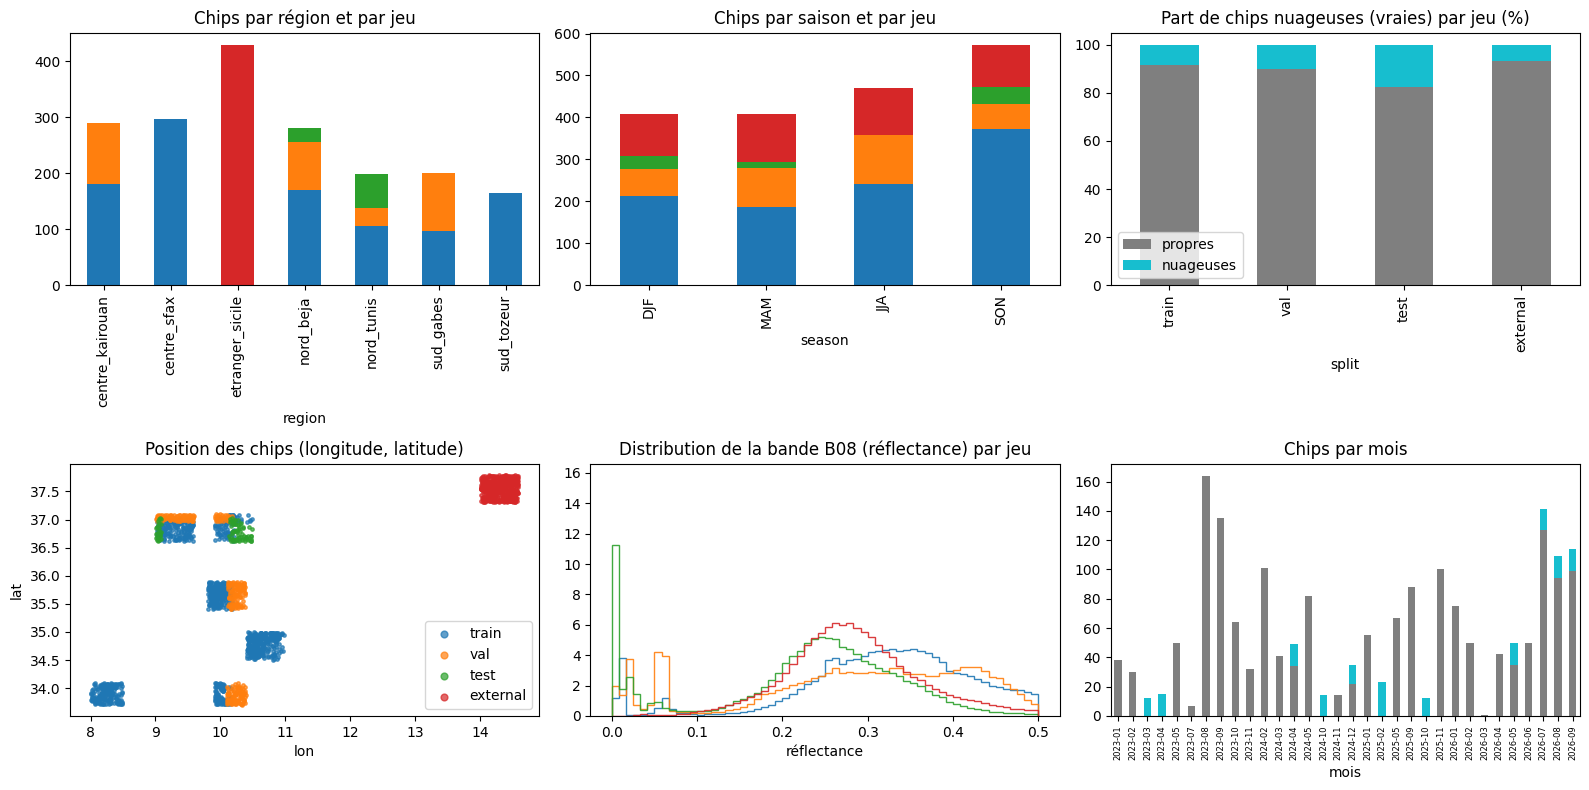

In [10]:
def show_rgb(x):
    rgb = x[[2, 1, 0]].astype(np.float32); lo, hi = np.percentile(rgb, [2, 98])
    return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1).transpose(1, 2, 0)
colors = {'train': 'tab:blue', 'val': 'tab:orange', 'test': 'tab:green', 'external': 'tab:red'}

fig, axs = plt.subplots(2, 3, figsize=(16, 8))
pd.crosstab(meta.region, meta.split)[list(colors)].plot.bar(ax=axs[0, 0], stacked=True, color=list(colors.values()), legend=False)
axs[0, 0].set_title('Chips par région et par jeu')
pd.crosstab(meta.season, meta.split).reindex(SEASONS)[list(colors)].plot.bar(ax=axs[0, 1], stacked=True, color=list(colors.values()), legend=False)
axs[0, 1].set_title('Chips par saison et par jeu')
(pd.crosstab(meta.split, meta.hard, normalize='index').reindex(list(colors)) * 100).plot.bar(ax=axs[0, 2], stacked=True, color=['tab:gray', 'tab:cyan'])
axs[0, 2].set_title('Part de chips nuageuses (vraies) par jeu (%)'); axs[0, 2].legend(['propres', 'nuageuses'])
for s, c in colors.items():
    m = meta[meta.split == s]
    axs[1, 0].scatter(m.lon, m.lat, s=6, c=c, label=s, alpha=0.7)
axs[1, 0].set_title('Position des chips (longitude, latitude)'); axs[1, 0].legend(markerscale=2); axs[1, 0].set_xlabel('lon'); axs[1, 0].set_ylabel('lat')
for bi, b in enumerate(BANDS):
    for s, c in colors.items():
        ii = meta.index[meta.split == s].values
        if len(ii) == 0: continue
        pick = np.random.default_rng(0).choice(ii, size=min(60, len(ii)), replace=False)
        v = np.concatenate([((X[i, bi].astype(np.float32) - meta.offset[i]) / 10000.0)[::4, ::4].ravel() for i in pick])
        axs[1, 1].hist(v, bins=60, range=(0, 0.5), histtype='step', color=c, density=True, alpha=0.9 if bi == 3 else 0.0)
axs[1, 1].set_title('Distribution de la bande B08 (réflectance) par jeu'); axs[1, 1].set_xlabel('réflectance')
meta.assign(mois=meta.date.str[:7]).groupby(['mois', 'hard']).size().unstack(fill_value=0).plot.bar(stacked=True, ax=axs[1, 2], color=['tab:gray', 'tab:cyan'], legend=False)
axs[1, 2].set_title('Chips par mois'); axs[1, 2].tick_params(axis='x', labelsize=6)
plt.tight_layout(); plt.show()

In [11]:
rs = np.random.default_rng(3)
fig, axs = plt.subplots(4, 8, figsize=(18, 9.5))
for r_, s in enumerate(['train', 'val', 'test', 'external']):
    ii = meta.index[(meta.split == s) & (~meta.hard)].values
    for c_, i in enumerate(rs.choice(ii, size=min(8, len(ii)), replace=False)):
        axs[r_, c_].imshow(show_rgb(X[i])); axs[r_, c_].axis('off'); axs[r_, c_].set_title(f'{meta.region[i][:12]} {meta.date[i][:7]}', fontsize=7)
    axs[r_, 0].text(-0.1, 0.5, s, transform=axs[r_, 0].transAxes, rotation=90, va='center', ha='right', fontsize=11)
plt.suptitle('Chips propres tirées au hasard dans chaque jeu'); plt.tight_layout(); plt.show()

hi = meta.index[meta.hard].values
if len(hi):
    fig, axs = plt.subplots(2, 8, figsize=(18, 5))
    for ax in axs.ravel(): ax.axis('off')
    for ax, i in zip(axs.ravel(), rs.choice(hi, size=min(16, len(hi)), replace=False)):
        ax.imshow(show_rgb(X[i])); ax.set_title(f'{meta.split[i]} nuage {meta.bad_frac[i]:.0%} brume {meta.haze_frac[i]:.0%}', fontsize=7)
    plt.suptitle('Chips AUTHENTIQUES difficiles (vrais nuages, ombres, neige, brume) : négatifs réels'); plt.tight_layout(); plt.show()

## 8. Statistiques de normalisation (jeu d'entraînement seulement) et sauvegarde

Les moyennes et écarts-types sont calculés **uniquement sur l'entraînement**. Chaque fichier reçoit une empreinte **SHA-256** consignée dans `data_manifest.json` : le notebook d'entraînement la revérifie au chargement et s'arrête si un fichier a été corrompu ou modifié.

In [12]:
tr_idx = meta.index[meta.split == 'train'].values
pick = np.random.default_rng(SEED).choice(tr_idx, size=min(600, len(tr_idx)), replace=False)
vals = np.stack([np.clip((X[i].astype(np.float32) - meta.offset[i]) / 10000.0, 0, 1.5) for i in pick])
band_stats = {'bands': BANDS, 'mean': vals.mean(axis=(0, 2, 3)).tolist(), 'std': vals.std(axis=(0, 2, 3)).tolist()}
del vals
print(band_stats)

def file_sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

for old in OUT.iterdir():
    old.unlink()
cols = ['region', 'role', 'scene', 'tile', 'date', 'season', 'cloud_scene', 'baseline', 'offset', 'r0', 'c0', 'bad_frac',
        'haze_frac', 'hard', 'epsg', 'x0', 'y0', 'lon', 'lat', 'split']
for s in ['train', 'val', 'test', 'external']:
    m = meta[meta.split == s]
    np.save(OUT / f'{s}_x.npy', X[m.index.values])
    np.save(OUT / f'{s}_off.npy', m['offset'].values.astype(np.float32))
    m[cols].reset_index(drop=True).to_csv(OUT / f'{s}_meta.csv', index=False)
json.dump(band_stats, open(OUT / 'band_stats.json', 'w'))
files = {f.name: file_sha256(f) for f in sorted(OUT.iterdir())}
json.dump({'files': files, 'split_group': GROUP, 'seed': SEED, 'counts': meta.split.value_counts().to_dict(),
           'created': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())}, open(OUT / 'data_manifest.json', 'w'), indent=1)
size_gb = sum(f.stat().st_size for f in OUT.iterdir()) / 1e9
print(sorted(f.name for f in OUT.iterdir()), f'\n{size_gb:.2f} Go | répartition :', meta.split.value_counts().to_dict())

{'bands': ['B02', 'B03', 'B04', 'B08'], 'mean': [0.12408356747690821, 0.1821797478230793, 0.2459111250991822, 0.33881082834370885], 'std': [0.057275767311417675, 0.0772294103065924, 0.1163847098093816, 0.11993612474655439]}
['band_stats.json', 'data_manifest.json', 'external_meta.csv', 'external_off.npy', 'external_x.npy', 'test_meta.csv', 'test_off.npy', 'test_x.npy', 'train_meta.csv', 'train_off.npy', 'train_x.npy', 'val_meta.csv', 'val_off.npy', 'val_x.npy'] 
0.98 Go | répartition : {'train': 1013, 'external': 429, 'val': 332, 'test': 86}


## 9. Publier le jeu de données

**Kaggle :** *Save Version* → *Save & Run All (Commit)*. Quand c'est terminé : onglet **Output** → **New Dataset** → nom `tp-data` → *Create*. Dans les notebooks 02 et 03 : **Add Input** → *Your Datasets* → `tp-data`.

**Colab :** exécutez la cellule suivante pour copier le dossier sur Google Drive.

**QGIS (optionnel) :** chaque chip porte sa projection et son coin haut-gauche (`epsg`, `x0`, `y0`). La fonction `export_geotiff` de la bibliothèque (notebook 02) crée un GeoTIFF à ouvrir dans QGIS (*Couche → Ajouter une couche → Ajouter une couche raster*).

In [13]:
if (not IN_KAGGLE) and Path('/content').exists():
    from google.colab import drive
    drive.mount('/content/drive')
    dst = Path('/content/drive/MyDrive/trust_the_pixel'); dst.mkdir(parents=True, exist_ok=True)
    !cp -r {OUT} {dst}/
    print('copié vers', dst)
else:
    print('Kaggle : Save Version puis New Dataset (voir ci-dessus).')

Kaggle : Save Version puis New Dataset (voir ci-dessus).
